<a href="https://colab.research.google.com/github/ikmalsworld/CVRP-Discrete-PSO/blob/main/Vehicle_Routing_Problem_IDM_Jakut.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Vehicle Routing Problem Indomaret Jakarta Utara**

# Data preparation and ORS matrix

In [9]:
BASE_DIR = os.environ.get("PSO_BASE_DIR", "/content")
OUT_DIR = os.path.join(BASE_DIR, "results")
os.makedirs(OUT_DIR, exist_ok=True)

DATA_PATH = f"{BASE_DIR}/LocIDMJakut.csv"
MATRIX_PATH = f"{BASE_DIR}/ors_distance_matrix.npy"
CLEAN_DATA_PATH = f"{BASE_DIR}/locations_clean.csv"

# QUICK=True shrinks every experiment (smoke test only). Keep False for real results.
QUICK = os.environ.get("PSO_QUICK") == "1"
# Experiments cache their results in OUT_DIR so a Colab disconnect doesn't lose hours of work.
# Set True to ignore caches and recompute everything.
FORCE_RERUN = False

In [10]:
import openrouteservice
from google.colab import userdata

df = pd.read_csv(DATA_PATH)
df = df.drop(columns=["Unnamed: 0"], errors="ignore")

# Put depot (ID 1) first
depot_df = df[df["id"] == 1]
customer_df = df[df["id"] != 1]

assert len(depot_df) == 1, "Exactly one depot with ID 1 is required."

df = pd.concat([depot_df, customer_df], ignore_index=True)

# Parse coordinates
df["coordinates"] = df["coordinates"].apply(ast.literal_eval)
df["latitude"] = df["coordinates"].apply(lambda x: x[0])
df["longitude"] = df["coordinates"].apply(lambda x: x[1])

# ORS expects [longitude, latitude]
locations = df[["longitude", "latitude"]].values.tolist()

assert df.iloc[0]["id"] == 1
assert len(df) == 46
assert df["id"].is_unique

ors_key = userdata.get("ORS_API_KEY")
if not ors_key:
    raise ValueError("ORS_API_KEY is missing from Colab Secrets.")

client = openrouteservice.Client(
    key=ors_key,
    base_url="https://api.heigit.org/openrouteservice"
)

if os.path.exists(MATRIX_PATH):
    distance_matrix = np.load(MATRIX_PATH)
    print("Loaded cached ORS distance matrix.")
else:
    print("Requesting ORS driving distance matrix...")
    response = client.distance_matrix(
        locations=locations,
        profile="driving-car",
        metrics=["distance"],
        units="m"
    )
    distance_matrix = np.array(response["distances"])
    np.save(MATRIX_PATH, distance_matrix)
    print("ORS distance matrix saved.")

assert distance_matrix.shape == (len(df), len(df))
assert np.isfinite(distance_matrix).all()
assert (distance_matrix >= 0).all()

df.to_csv(CLEAN_DATA_PATH, index=False)

print("\nDATASET SUMMARY")
print("----------------------------")
print("Total locations:", len(df))
print("Depot:", df.iloc[0]["loc_name"])
print("Customers:", len(df) - 1)
print("Distance matrix:", distance_matrix.shape)
print(f"Depot to first customer: {distance_matrix[0, 1] / 1000:.3f} km")
asym = np.abs(distance_matrix - distance_matrix.T).max() / 1000
print(f"Max |d(i,j) - d(j,i)|: {asym:.3f} km  (road network is directed, matrix is asymmetric)")

Requesting ORS driving distance matrix...
ORS distance matrix saved.

DATASET SUMMARY
----------------------------
Total locations: 46
Depot: Indomarco
Customers: 45
Distance matrix: (46, 46)
Depot to first customer: 5.477 km
Max |d(i,j) - d(j,i)|: 13.093 km  (road network is directed, matrix is asymmetric)


# CVRP formulation and decoder

In [11]:
RANDOM_SEED = 42
VEHICLE_CAPACITY = 100

rng = np.random.default_rng(RANDOM_SEED)
demands = np.zeros(len(df), dtype=int)
demands[1:] = rng.integers(low=10, high=50, size=len(df) - 1)

assert demands[0] == 0
assert np.all(demands[1:] > 0)
assert np.all(demands[1:] <= VEHICLE_CAPACITY)

df["demand"] = demands
df.to_csv(f"{BASE_DIR}/locations_with_demand.csv", index=False)

print("CVRP PROBLEM DEFINITION")
print("----------------------------")
print("Customer count:", len(demands) - 1)
print("Vehicle capacity:", VEHICLE_CAPACITY)
print("Total demand:", demands.sum())
print("Minimum theoretical vehicles:", int(np.ceil(demands.sum() / VEHICLE_CAPACITY)))

N_CUSTOMERS = len(df) - 1
CUSTOMER_INDICES = np.arange(N_CUSTOMERS)


def decode_solution(permutation):
    """Permutation of customers -> capacity-feasible routes (greedy split).
    Customer index k corresponds to distance-matrix index k + 1."""
    routes, current_route, current_load = [], [], 0
    for customer_idx in permutation:
        demand = demands[customer_idx + 1]
        if current_load + demand > VEHICLE_CAPACITY:
            if current_route:
                routes.append(current_route)
            current_route, current_load = [], 0
        current_route.append(customer_idx)
        current_load += demand
    if current_route:
        routes.append(current_route)
    return routes


def calculate_route_distance(route):
    """Depot -> customers -> depot distance (metres)."""
    if not route:
        return 0.0
    distance, previous_location = 0.0, 0
    for customer_idx in route:
        current_location = customer_idx + 1
        distance += distance_matrix[previous_location, current_location]
        previous_location = current_location
    distance += distance_matrix[previous_location, 0]
    return distance


def evaluate_solution(permutation):
    """Full, validated evaluation (use for reporting / tests)."""
    permutation = np.asarray(permutation, dtype=int)
    if len(permutation) != N_CUSTOMERS or not np.array_equal(np.sort(permutation), CUSTOMER_INDICES):
        raise ValueError("Invalid customer permutation.")
    routes = decode_solution(permutation)
    vehicle_loads, vehicle_distances = [], []
    for route in routes:
        route_load = sum(demands[c + 1] for c in route)
        if route_load > VEHICLE_CAPACITY:
            raise ValueError("Vehicle capacity exceeded.")
        vehicle_loads.append(route_load)
        vehicle_distances.append(calculate_route_distance(route))
    return {
        "total_distance": sum(vehicle_distances),
        "routes": routes,
        "vehicle_loads": vehicle_loads,
        "vehicle_distances": vehicle_distances,
        "vehicle_count": len(routes),
    }


# FIX/NEW: fast objective used inside every optimiser (same value as evaluate_solution)
_D = distance_matrix.tolist()
_DEM = demands.tolist()


def fast_fitness(perm):
    total, load, prev = 0.0, 0, 0
    for c in perm:
        loc = int(c) + 1
        d = _DEM[loc]
        if load + d > VEHICLE_CAPACITY:
            total += _D[prev][0]
            prev, load = 0, 0
        total += _D[prev][loc]
        prev = loc
        load += d
    return total + _D[prev][0]


class EvalTracker:
    """Fitness wrapper that counts evaluations and records best-so-far.
    Giving every algorithm one of these guarantees an equal evaluation budget."""

    def __init__(self, budget):
        self.budget, self.count = budget, 0
        self.best, self.best_perm, self.history = float("inf"), None, []

    def __call__(self, perm):
        if self.count >= self.budget:
            raise RuntimeError("Evaluation budget exceeded")
        self.count += 1
        cost = fast_fitness(perm)
        if cost < self.best:
            self.best, self.best_perm = cost, np.array(perm, dtype=int)
        self.history.append(self.best)
        return cost

    @property
    def remaining(self):
        return self.budget - self.count


# consistency test: fast objective == validated objective
_t = np.random.default_rng(0)
for _ in range(200):
    p = _t.permutation(CUSTOMER_INDICES)
    assert abs(fast_fitness(p) - evaluate_solution(p)["total_distance"]) < 1e-6
print("\nfast_fitness matches evaluate_solution on 200 random permutations.")

CVRP PROBLEM DEFINITION
----------------------------
Customer count: 45
Vehicle capacity: 100
Total demand: 1364
Minimum theoretical vehicles: 14

fast_fitness matches evaluate_solution on 200 random permutations.


# Random baseline

In [12]:
N_BASELINE_RUNS = 100
baseline_rng = np.random.default_rng(2026)
baseline_results = []
for run in range(N_BASELINE_RUNS):
    permutation = baseline_rng.permutation(CUSTOMER_INDICES)
    result = evaluate_solution(permutation)
    baseline_results.append({"run": run + 1, "total_distance": result["total_distance"],
                             "vehicle_count": result["vehicle_count"]})
baseline_df = pd.DataFrame(baseline_results)

print("RANDOM BASELINE RESULTS")
print("----------------------------")
print(f"Best distance:  {baseline_df['total_distance'].min():,.2f} m")
print(f"Mean distance:  {baseline_df['total_distance'].mean():,.2f} m")
print(f"Worst distance: {baseline_df['total_distance'].max():,.2f} m")
print(f"Std deviation:  {baseline_df['total_distance'].std():,.2f} m")
print(f"Average vehicles: {baseline_df['vehicle_count'].mean():.2f}")
baseline_df.to_csv(f"{OUT_DIR}/random_baseline_results.csv", index=False)

RANDOM BASELINE RESULTS
----------------------------
Best distance:  773,773.19 m
Mean distance:  870,586.44 m
Worst distance: 984,114.56 m
Std deviation:  38,726.99 m
Average vehicles: 16.77


# Initial discrete PSO

In [13]:
def measure_swarm_diversity(positions):
    """FIX: moved above run_discrete_pso. Returns (#unique permutations, mean pairwise
    proportion of differing positions). Vectorised, same result as the original loop."""
    n = len(positions)
    P = np.asarray(positions)
    unique_positions = len({tuple(p) for p in P})
    if n < 2:
        return unique_positions, 0.0
    diffs = [(P[i] != P[i + 1:]).mean(axis=1) for i in range(n - 1)]
    return unique_positions, float(np.concatenate(diffs).mean())


def permutation_difference(source, target):
    """Swaps that transform source into target."""
    working = list(source)
    swaps = []
    for i in range(len(working)):
        if working[i] != target[i]:
            j = working.index(target[i], i + 1)
            working[i], working[j] = working[j], working[i]
            swaps.append((i, j))
    return swaps


def apply_swaps(permutation, swaps):
    result = list(permutation)
    for i, j in swaps:
        result[i], result[j] = result[j], result[i]
    return np.array(result, dtype=int)


def sample_swaps(swaps, coefficient, rng):
    """Random subset of swaps; expected proportion ~ coefficient/2 (capped at 100%)."""
    if not swaps:
        return []
    count = min(int(round(coefficient * rng.random() * len(swaps))), len(swaps))
    if count == 0:
        return []
    selected = sorted(rng.choice(len(swaps), size=count, replace=False))
    return [swaps[i] for i in selected]


def run_discrete_pso(n_particles=30, n_iter=200, w=0.7, c1=1.5, c2=1.5, seed=42,
                     verbose=True, fitness_fn=None, collect_diagnostics=True):
    """Discrete PSO for CVRP. Position = customer permutation, velocity = swap sequence.
    Evaluations used = n_particles * (n_iter + 1)."""
    fit = fitness_fn if fitness_fn is not None else fast_fitness
    rng = np.random.default_rng(seed)

    positions = [rng.permutation(CUSTOMER_INDICES) for _ in range(n_particles)]
    velocities = [[] for _ in range(n_particles)]
    pbest_positions = [p.copy() for p in positions]
    pbest_scores = np.array([fit(p) for p in positions])

    best_idx = int(np.argmin(pbest_scores))
    gbest_position = pbest_positions[best_idx].copy()
    gbest_score = pbest_scores[best_idx]
    convergence_history = [gbest_score]
    max_velocity = 2 * N_CUSTOMERS

    diagnostics = []
    if collect_diagnostics:
        u, dv = measure_swarm_diversity(positions)
        diagnostics.append({"iteration": 0, "unique_positions": u, "diversity": dv,
                            "particles_moved": 0, "pbest_improvements": 0,
                            "avg_velocity_length": 0.0, "max_velocity_particles": 0,
                            "gbest_improved": False, "gbest_score": gbest_score})
    if verbose:
        print(f"Initial best fitness: {gbest_score:.2f} meters")

    for iteration in range(n_iter):
        iteration_gbest = gbest_position.copy()
        particles_moved = pbest_improvements = max_velocity_particles = 0

        for i in range(n_particles):
            old_position = positions[i]
            current = positions[i].copy()
            new_velocity = []

            # A. inertia
            s = sample_swaps(velocities[i], w, rng)
            current = apply_swaps(current, s); new_velocity.extend(s)
            # B. cognitive
            s = sample_swaps(permutation_difference(current, pbest_positions[i]), c1, rng)
            current = apply_swaps(current, s); new_velocity.extend(s)
            # C. social
            s = sample_swaps(permutation_difference(current, iteration_gbest), c2, rng)
            current = apply_swaps(current, s); new_velocity.extend(s)

            # D. velocity limit
            if len(new_velocity) > max_velocity:
                new_velocity = new_velocity[-max_velocity:]
            if len(new_velocity) >= max_velocity:
                max_velocity_particles += 1

            # E. update
            positions[i], velocities[i] = current, new_velocity
            if not np.array_equal(old_position, current):
                particles_moved += 1
            score = fit(current)

            # F. personal best
            if score < pbest_scores[i]:
                pbest_positions[i], pbest_scores[i] = current.copy(), score
                pbest_improvements += 1

        best_idx = int(np.argmin(pbest_scores))
        gbest_improved = False
        if pbest_scores[best_idx] < gbest_score:
            gbest_score = pbest_scores[best_idx]
            gbest_position = pbest_positions[best_idx].copy()
            gbest_improved = True
            if verbose:
                print(f"Iteration {iteration + 1}/{n_iter} -> New global best: {gbest_score:.2f} meters")
        convergence_history.append(gbest_score)

        if collect_diagnostics:
            u, dv = measure_swarm_diversity(positions)
            diagnostics.append({"iteration": iteration + 1, "unique_positions": u, "diversity": dv,
                                "particles_moved": particles_moved,
                                "pbest_improvements": pbest_improvements,
                                "avg_velocity_length": float(np.mean([len(v) for v in velocities])),
                                "max_velocity_particles": max_velocity_particles,
                                "gbest_improved": gbest_improved, "gbest_score": gbest_score})
        if verbose and (iteration + 1) % 20 == 0:
            print(f"Iteration {iteration + 1}/{n_iter} | Best: {gbest_score:.2f} meters")

    final = evaluate_solution(gbest_position)
    return {
        "best_position": gbest_position, "best_score": gbest_score,
        "routes": final["routes"], "vehicle_count": final["vehicle_count"],
        "vehicle_loads": final["vehicle_loads"], "vehicle_distances": final["vehicle_distances"],
        "convergence_history": convergence_history,
        "diagnostics": pd.DataFrame(diagnostics),
    }

In [14]:
N_RUNS = 2 if QUICK else 5
N_PARTICLES = 30
N_ITERATIONS = 30 if QUICK else 200

pso_results, best_overall = [], None
for run in range(N_RUNS):
    print(f"\n{'=' * 20} RUN {run + 1}/{N_RUNS} {'=' * 20}")
    result = run_discrete_pso(n_particles=N_PARTICLES, n_iter=N_ITERATIONS, w=0.7, c1=1.5, c2=1.5,
                              seed=1000 + run, verbose=(run == 0))
    pso_results.append(result)
    print(f"Run {run + 1}: best {result['best_score']:.2f} m, vehicles {result['vehicle_count']}")
    if best_overall is None or result["best_score"] < best_overall["best_score"]:
        best_overall = result

pso_scores = [r["best_score"] for r in pso_results]
pd.DataFrame({"run": range(1, N_RUNS + 1), "best_distance": pso_scores,
              "vehicle_count": [r["vehicle_count"] for r in pso_results]}
             ).to_csv(f"{OUT_DIR}/discrete_pso_initial_results.csv", index=False)

print("\nDISCRETE PSO RESULTS (initial settings)")
print(f"Best {np.min(pso_scores):,.0f} m | Mean {np.mean(pso_scores):,.0f} m | "
      f"Worst {np.max(pso_scores):,.0f} m | Std {np.std(pso_scores):,.0f} m")
print(f"Random baseline mean {baseline_df['total_distance'].mean():,.0f} m -> "
      f"PSO is {100 * (1 - np.mean(pso_scores) / baseline_df['total_distance'].mean()):.1f}% shorter")


==================== RUN 1/5 ====================
Initial best fitness: 807328.39 meters
Iteration 1/200 -> New global best: 765538.62 meters
Iteration 2/200 -> New global best: 757167.78 meters
Iteration 3/200 -> New global best: 751559.05 meters
Iteration 4/200 -> New global best: 729746.62 meters
Iteration 5/200 -> New global best: 722096.58 meters
Iteration 6/200 -> New global best: 720203.58 meters
Iteration 7/200 -> New global best: 712786.64 meters
Iteration 8/200 -> New global best: 706133.73 meters
Iteration 9/200 -> New global best: 695346.52 meters
Iteration 11/200 -> New global best: 694708.29 meters
Iteration 13/200 -> New global best: 688608.90 meters
Iteration 14/200 -> New global best: 687339.26 meters
Iteration 20/200 | Best: 687339.26 meters
Iteration 40/200 | Best: 687339.26 meters
Iteration 60/200 | Best: 687339.26 meters
Iteration 80/200 | Best: 687339.26 meters
Iteration 100/200 | Best: 687339.26 meters
Iteration 120/200 | Best: 687339.26 meters
Iteration 140/200

# PSO diagnostics

,run,best_distance_km,final_diversity,first_iter_diversity<5%,unique_positions_final,last_gbest_improvement_iter,stagnant_iters_%,particles_moved_last25%,pbest_improv_last25%,mean_velocity_len,iters_with_capped_particles_%
0,1,687.339,0.0,9,1,14,93.0,0.0,0.0,0.879,0.0
1,2,718.342,0.0,10,1,8,96.0,0.0,0.0,0.772,0.0
2,3,724.317,0.0,6,1,7,96.5,0.0,0.0,0.576,0.0
3,4,728.772,0.0,11,1,10,95.0,0.0,0.0,0.899,0.0
4,5,737.351,0.0,10,1,12,94.0,0.0,0.0,0.948,0.0


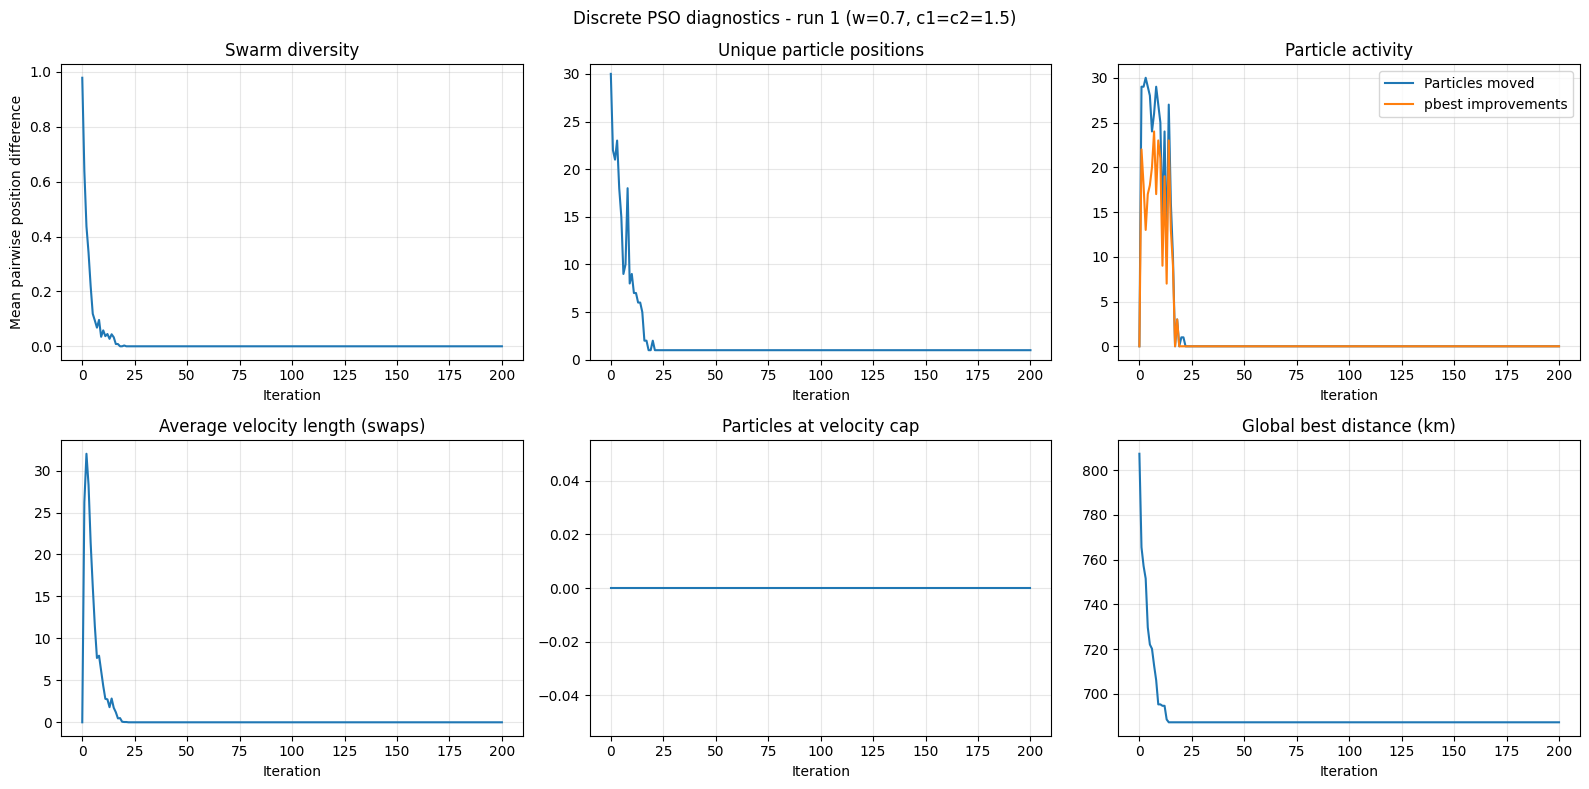

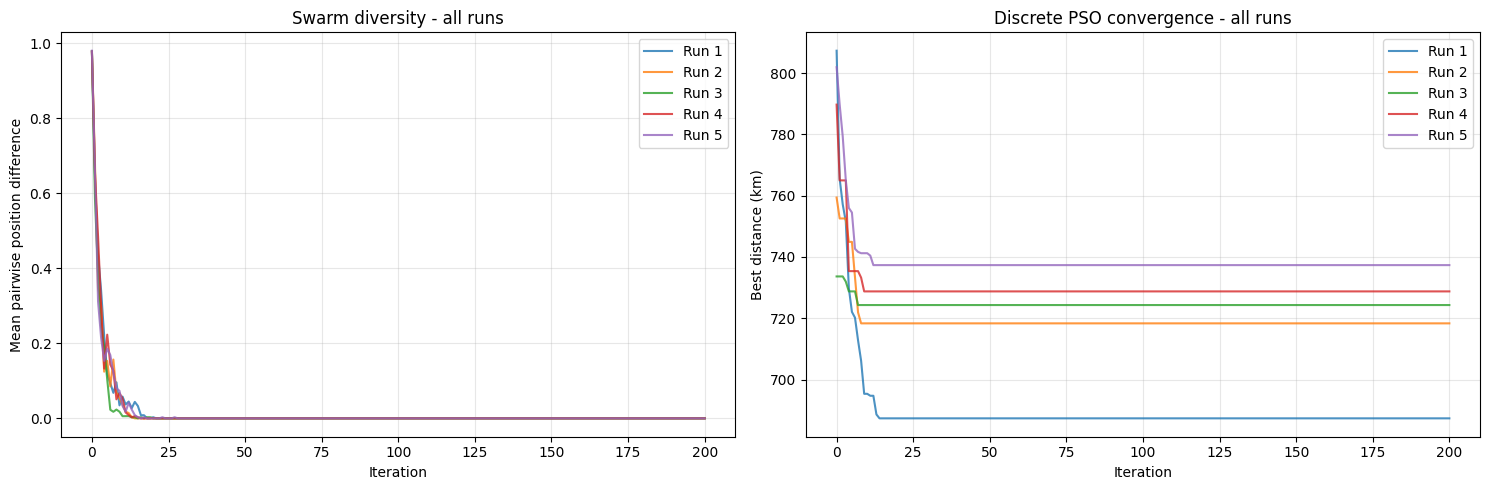

In [15]:
diag_runs = [r["diagnostics"] for r in pso_results]


def summarize_diag(d, n_iter):
    improved = d.loc[d["gbest_improved"], "iteration"]
    last_imp = int(improved.max()) if len(improved) else 0
    below = d.loc[d["diversity"] < 0.05, "iteration"]
    tail = d.iloc[-max(1, n_iter // 4):]
    return {
        "final_diversity": d["diversity"].iloc[-1],
        "first_iter_diversity<5%": int(below.min()) if len(below) else None,
        "unique_positions_final": int(d["unique_positions"].iloc[-1]),
        "last_gbest_improvement_iter": last_imp,
        "stagnant_iters_%": 100 * (n_iter - last_imp) / n_iter,
        "particles_moved_last25%": tail["particles_moved"].mean(),
        "pbest_improv_last25%": tail["pbest_improvements"].mean(),
        "mean_velocity_len": d["avg_velocity_length"].iloc[1:].mean(),
        "iters_with_capped_particles_%": 100 * (d["max_velocity_particles"].iloc[1:] > 0).mean(),
    }


diag_summary = pd.DataFrame([summarize_diag(d, N_ITERATIONS) for d in diag_runs])
diag_summary.insert(0, "run", range(1, N_RUNS + 1))
diag_summary.insert(1, "best_distance_km", [s / 1000 for s in pso_scores])
display(diag_summary.round(3))
diag_summary.to_csv(f"{OUT_DIR}/pso_diagnostics_summary.csv", index=False)

d0 = diag_runs[0]
fig, ax = plt.subplots(2, 3, figsize=(16, 8))
ax = ax.ravel()
ax[0].plot(d0["iteration"], d0["diversity"]); ax[0].set_title("Swarm diversity"); ax[0].set_ylabel("Mean pairwise position difference")
ax[1].plot(d0["iteration"], d0["unique_positions"]); ax[1].set_title("Unique particle positions"); ax[1].set_ylim(0, N_PARTICLES + 1)
ax[2].plot(d0["iteration"], d0["particles_moved"], label="Particles moved")
ax[2].plot(d0["iteration"], d0["pbest_improvements"], label="pbest improvements"); ax[2].legend(); ax[2].set_title("Particle activity")
ax[3].plot(d0["iteration"], d0["avg_velocity_length"]); ax[3].set_title("Average velocity length (swaps)")
ax[4].plot(d0["iteration"], d0["max_velocity_particles"]); ax[4].set_title("Particles at velocity cap")
ax[5].plot(d0["iteration"], d0["gbest_score"] / 1000); ax[5].set_title("Global best distance (km)")
for a in ax:
    a.set_xlabel("Iteration"); a.grid(alpha=0.3)
fig.suptitle("Discrete PSO diagnostics - run 1 (w=0.7, c1=c2=1.5)")
fig.tight_layout(); fig.savefig(f"{OUT_DIR}/fig_pso_diagnostics_run1.png", dpi=150); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
for i, (r, d) in enumerate(zip(pso_results, diag_runs)):
    ax[0].plot(d["iteration"], d["diversity"], alpha=0.8, label=f"Run {i + 1}")
    ax[1].plot(np.array(r["convergence_history"]) / 1000, alpha=0.8, label=f"Run {i + 1}")
ax[0].set_title("Swarm diversity - all runs"); ax[0].set_ylabel("Mean pairwise position difference")
ax[1].set_title("Discrete PSO convergence - all runs"); ax[1].set_ylabel("Best distance (km)")
for a in ax:
    a.set_xlabel("Iteration"); a.grid(alpha=0.3); a.legend()
fig.tight_layout(); fig.savefig(f"{OUT_DIR}/fig_pso_diagnostics_all_runs.png", dpi=150); plt.show()

# Parameter Experimentation

In [16]:
BUDGET = 600 if QUICK else 6000                       # fitness evaluations per run
TUNE_SEEDS = [100, 101] if QUICK else list(range(100, 105))
CONFIRM_SEEDS = [200] if QUICK else list(range(200, 210))
FINAL_SEEDS = list(range(2000, 2003)) if QUICK else list(range(2000, 2030))
GRID_W = [0.5, 0.9] if QUICK else [0.3, 0.5, 0.7, 0.9]
GRID_C = [0.5, 1.5] if QUICK else [0.25, 0.5, 1.0, 1.5]
SWARM_SIZES = [10, 30, 100] if QUICK else [10, 20, 30, 50, 100]
DEFAULT_CFG = dict(n_particles=30, w=0.7, c1=1.5, c2=1.5)   # original settings


def run_pso_config(n_particles, w, c1, c2, seed, budget=BUDGET):
    tr = EvalTracker(budget)
    res = run_discrete_pso(n_particles=n_particles, n_iter=budget // n_particles - 1, w=w, c1=c1, c2=c2,
                           seed=seed, verbose=False, fitness_fn=tr, collect_diagnostics=False)
    assert tr.count == budget, (tr.count, budget)
    return tr, res


from tqdm.auto import tqdm

grid:   0%|          | 0/64 [00:00<?, ?it/s]

Grid finished in 169s
Top 10 configurations (mean best distance over tuning seeds, km):


,w,c1,c2,mean,std,best
57,0.9,1.0,0.50,614.792,20.267,582.523
61,0.9,1.5,0.50,616.379,15.088,599.012
41,0.7,1.0,0.50,616.839,16.599,597.592
24,0.5,1.0,0.25,616.881,13.877,595.264
13,0.3,1.5,0.50,618.057,8.632,606.845
29,0.5,1.5,0.50,618.865,27.096,587.554
45,0.7,1.5,0.50,618.938,27.442,592.024
25,0.5,1.0,0.50,622.070,4.400,616.160
36,0.7,0.5,0.25,622.301,24.466,584.029
9,0.3,1.0,0.50,624.259,17.293,610.670


Worst 5:


,w,c1,c2,mean,std,best
7,0.3,0.50,1.5,723.185,16.144,702.198
27,0.5,1.00,1.5,724.356,19.031,709.697
11,0.3,1.00,1.5,726.366,27.337,699.558
31,0.5,1.50,1.5,731.407,28.251,703.463
3,0.3,0.25,1.5,733.709,14.452,716.182


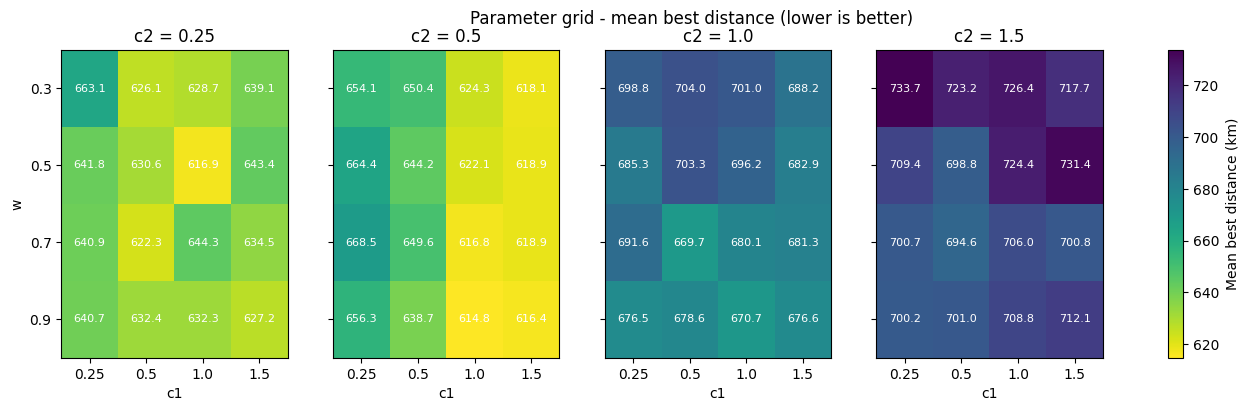

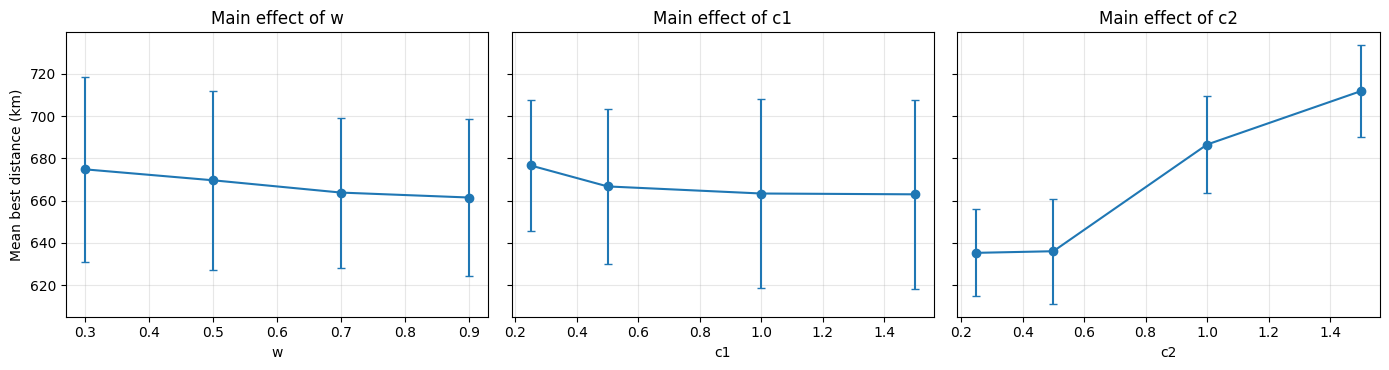

In [17]:
GRID_PATH = f"{OUT_DIR}/tuning_grid_results.csv"
if os.path.exists(GRID_PATH) and not FORCE_RERUN:
    grid_df = pd.read_csv(GRID_PATH)
    print("Loaded cached grid results.")
else:
    records = []
    combos = [(w, c1, c2) for w in GRID_W for c1 in GRID_C for c2 in GRID_C]
    t0 = time.time()
    for w, c1, c2 in tqdm(combos, desc="grid"):
        for seed in TUNE_SEEDS:
            tr, res = run_pso_config(30, w, c1, c2, seed)
            records.append({"w": w, "c1": c1, "c2": c2, "seed": seed,
                            "best_km": tr.best / 1000, "vehicles": res["vehicle_count"]})
    grid_df = pd.DataFrame(records)
    grid_df.to_csv(GRID_PATH, index=False)
    print(f"Grid finished in {time.time() - t0:.0f}s")

grid_summary = (grid_df.groupby(["w", "c1", "c2"])["best_km"]
                .agg(mean="mean", std="std", best="min").reset_index().sort_values("mean"))
print("Top 10 configurations (mean best distance over tuning seeds, km):")
display(grid_summary.head(10).round(3))
print("Worst 5:")
display(grid_summary.tail(5).round(3))

c2_vals = sorted(grid_df["c2"].unique())
vmin, vmax = grid_summary["mean"].min(), grid_summary["mean"].max()
fig, axes = plt.subplots(1, len(c2_vals), figsize=(4.2 * len(c2_vals), 4), sharey=True)
axes = np.atleast_1d(axes)
for ax_, c2v in zip(axes, c2_vals):
    pv = grid_summary[grid_summary["c2"] == c2v].pivot(index="w", columns="c1", values="mean")
    im = ax_.imshow(pv.values, vmin=vmin, vmax=vmax, cmap="viridis_r", aspect="auto")
    ax_.set_xticks(range(len(pv.columns))); ax_.set_xticklabels(pv.columns)
    ax_.set_yticks(range(len(pv.index))); ax_.set_yticklabels(pv.index)
    ax_.set_title(f"c2 = {c2v}"); ax_.set_xlabel("c1")
    for (r_, c_), v in np.ndenumerate(pv.values):
        ax_.text(c_, r_, f"{v:.1f}", ha="center", va="center", color="white", fontsize=8)
axes[0].set_ylabel("w")
fig.colorbar(im, ax=axes, label="Mean best distance (km)")
fig.suptitle("Parameter grid - mean best distance (lower is better)")
fig.savefig(f"{OUT_DIR}/fig_tuning_heatmaps.png", dpi=150, bbox_inches="tight"); plt.show()

# main effects
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for ax_, p in zip(axes, ["w", "c1", "c2"]):
    g = grid_df.groupby(p)["best_km"].agg(["mean", "std"])
    ax_.errorbar(g.index, g["mean"], yerr=g["std"], marker="o", capsize=3)
    ax_.set_title(f"Main effect of {p}"); ax_.set_xlabel(p); ax_.grid(alpha=0.3)
axes[0].set_ylabel("Mean best distance (km)")
fig.tight_layout(); fig.savefig(f"{OUT_DIR}/fig_tuning_main_effects.png", dpi=150); plt.show()

In [18]:
CONFIRM_PATH = f"{OUT_DIR}/tuning_confirm_results.csv"
top3 = grid_summary.head(3)[["w", "c1", "c2"]].values.tolist()
if os.path.exists(CONFIRM_PATH) and not FORCE_RERUN:
    confirm_df = pd.read_csv(CONFIRM_PATH)
    print("Loaded cached confirmation results.")
else:
    recs = []
    for w, c1, c2 in tqdm(top3, desc="confirm"):
        for seed in CONFIRM_SEEDS:
            tr, res = run_pso_config(30, w, c1, c2, seed)
            recs.append({"w": w, "c1": c1, "c2": c2, "seed": seed, "best_km": tr.best / 1000,
                         "vehicles": res["vehicle_count"]})
    confirm_df = pd.DataFrame(recs)
    confirm_df.to_csv(CONFIRM_PATH, index=False)

merged = pd.concat([grid_df.merge(pd.DataFrame(top3, columns=["w", "c1", "c2"])), confirm_df])
confirm_summary = (merged.groupby(["w", "c1", "c2"])["best_km"]
                   .agg(mean="mean", std="std", n="count").reset_index().sort_values("mean"))
display(confirm_summary.round(3))
BEST_W, BEST_C1, BEST_C2 = confirm_summary.iloc[0][["w", "c1", "c2"]].tolist()
print(f"Selected (w, c1, c2) = ({BEST_W}, {BEST_C1}, {BEST_C2})")

confirm:   0%|          | 0/3 [00:00<?, ?it/s]

,w,c1,c2,mean,std,n
2,0.9,1.5,0.5,615.205,14.069,15
1,0.9,1.0,0.5,616.312,16.380,15
0,0.7,1.0,0.5,622.736,16.576,15


Selected (w, c1, c2) = (0.9, 1.5, 0.5)


swarm size:   0%|          | 0/5 [00:00<?, ?it/s]

,n_particles,n_iter,mean,std,best
0,10,599,653.103,21.901,627.186
1,20,299,630.675,13.217,613.428
2,30,199,615.205,14.069,591.745
3,50,119,600.130,16.272,574.333
4,100,59,606.297,23.685,564.418


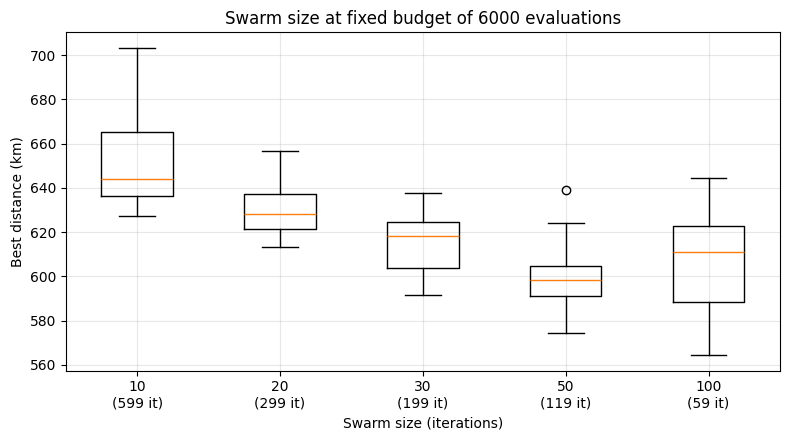

TUNED CONFIG: {'n_particles': 50, 'w': 0.9, 'c1': 1.5, 'c2': 0.5}
DEFAULT CONFIG: {'n_particles': 30, 'w': 0.7, 'c1': 1.5, 'c2': 1.5}


In [19]:
SWARM_PATH = f"{OUT_DIR}/tuning_swarm_size_results.csv"
SWARM_SEEDS = TUNE_SEEDS + CONFIRM_SEEDS
if os.path.exists(SWARM_PATH) and not FORCE_RERUN:
    swarm_df = pd.read_csv(SWARM_PATH)
    print("Loaded cached swarm-size results.")
else:
    recs = []
    for n in tqdm(SWARM_SIZES, desc="swarm size"):
        for seed in SWARM_SEEDS:
            tr, res = run_pso_config(n, BEST_W, BEST_C1, BEST_C2, seed)
            recs.append({"n_particles": n, "n_iter": BUDGET // n - 1, "seed": seed,
                         "best_km": tr.best / 1000, "vehicles": res["vehicle_count"]})
    swarm_df = pd.DataFrame(recs)
    swarm_df.to_csv(SWARM_PATH, index=False)

swarm_summary = (swarm_df.groupby(["n_particles", "n_iter"])["best_km"]
                 .agg(mean="mean", std="std", best="min").reset_index())
display(swarm_summary.round(3))
BEST_N = int(swarm_summary.sort_values("mean").iloc[0]["n_particles"])

fig, ax_ = plt.subplots(figsize=(8, 4.5))
ax_.boxplot([swarm_df[swarm_df.n_particles == n]["best_km"] for n in SWARM_SIZES])
ax_.set_xticks(range(1, len(SWARM_SIZES) + 1))
ax_.set_xticklabels([f"{n}\n({BUDGET // n - 1} it)" for n in SWARM_SIZES])
ax_.set_xlabel("Swarm size (iterations)"); ax_.set_ylabel("Best distance (km)")
ax_.set_title(f"Swarm size at fixed budget of {BUDGET} evaluations"); ax_.grid(alpha=0.3)
fig.tight_layout(); fig.savefig(f"{OUT_DIR}/fig_tuning_swarm_size.png", dpi=150); plt.show()

TUNED_CFG = dict(n_particles=BEST_N, w=BEST_W, c1=BEST_C1, c2=BEST_C2)
print("TUNED CONFIG:", TUNED_CFG)
print("DEFAULT CONFIG:", DEFAULT_CFG)
with open(f"{OUT_DIR}/tuned_config.json", "w") as f:
    json.dump({"tuned": TUNED_CFG, "default": DEFAULT_CFG, "budget": BUDGET}, f, indent=2)

# Equal-budget algorithm comparison

In [20]:
def _neighbor(perm, rng):
    """Random swap / insertion / reversal move on a copy of perm."""
    p = perm.copy()
    n = len(p)
    i, j = sorted(rng.choice(n, size=2, replace=False))
    move = rng.integers(3)
    if move == 0:                       # swap
        p[i], p[j] = p[j], p[i]
    elif move == 1:                     # insertion
        v = p[j]
        p = np.insert(np.delete(p, j), i, v)
    else:                               # reversal (2-opt on the giant tour)
        p[i:j + 1] = p[i:j + 1][::-1]
    return p


def _package(tr):
    ev = evaluate_solution(tr.best_perm)
    assert abs(ev["total_distance"] - tr.best) < 1e-6
    return {"best_score": tr.best, "best_perm": tr.best_perm, "vehicle_count": ev["vehicle_count"],
            "history": np.array(tr.history, dtype=np.float32), "evals": tr.count}


def run_random_search(budget, seed):
    rng = np.random.default_rng(seed)
    tr = EvalTracker(budget)
    while tr.remaining > 0:
        tr(rng.permutation(CUSTOMER_INDICES))
    return _package(tr)


def run_simulated_annealing(budget, seed, calib=50, end_ratio=0.005):
    rng = np.random.default_rng(seed)
    tr = EvalTracker(budget)
    x = rng.permutation(CUSTOMER_INDICES); xc = tr(x)
    deltas = []
    for _ in range(min(calib, tr.remaining)):          # accept-all random walk to calibrate T0
        y = _neighbor(x, rng); yc = tr(y)
        deltas.append(abs(yc - xc)); x, xc = y, yc
    T0 = max(float(np.mean(deltas)), 1e-9) if deltas else 1.0
    cur, cur_c = tr.best_perm.copy(), tr.best
    steps = max(tr.remaining, 1)
    alpha = end_ratio ** (1.0 / steps)
    T = T0
    while tr.remaining > 0:
        cand = _neighbor(cur, rng); cand_c = tr(cand)
        if cand_c <= cur_c or rng.random() < np.exp(-(cand_c - cur_c) / T):
            cur, cur_c = cand, cand_c
        T *= alpha
    return _package(tr)


def _order_crossover(p1, p2, rng):
    n = len(p1)
    a, b = sorted(rng.choice(n, size=2, replace=False))
    child = -np.ones(n, dtype=int)
    child[a:b + 1] = p1[a:b + 1]
    taken = set(p1[a:b + 1].tolist())
    fill = [g for g in p2 if g not in taken]
    child[child == -1] = fill
    return child


def run_genetic_algorithm(budget, seed, pop_size=30, elite=2, tourney=3, p_cx=0.9, p_mut=0.2):
    rng = np.random.default_rng(seed)
    tr = EvalTracker(budget)
    pop = [rng.permutation(CUSTOMER_INDICES) for _ in range(pop_size)]
    fit = np.array([tr(p) for p in pop])

    def select():
        idx = rng.choice(pop_size, size=tourney, replace=False)
        return pop[idx[np.argmin(fit[idx])]]

    while tr.remaining > 0:
        order = np.argsort(fit)
        new_pop = [pop[k].copy() for k in order[:elite]]
        new_fit = [fit[k] for k in order[:elite]]
        while len(new_pop) < pop_size and tr.remaining > 0:
            p1, p2 = select(), select()
            child = _order_crossover(p1, p2, rng) if rng.random() < p_cx else p1.copy()
            if rng.random() < p_mut:
                child = _neighbor(child, rng)
            new_pop.append(child); new_fit.append(tr(child))
        if len(new_pop) < pop_size:                      # budget ran out mid-generation
            break
        pop, fit = new_pop, np.array(new_fit)
    return _package(tr)


def run_pso_algo(budget, seed, cfg):
    tr = EvalTracker(budget)
    res = run_discrete_pso(n_particles=cfg["n_particles"], n_iter=budget // cfg["n_particles"] - 1,
                           w=cfg["w"], c1=cfg["c1"], c2=cfg["c2"], seed=seed, verbose=False,
                           fitness_fn=tr, collect_diagnostics=False)
    assert tr.count == budget
    assert abs(res["best_score"] - tr.best) < 1e-6
    return _package(tr)


def clarke_wright_savings():
    """Classic savings heuristic (reference). Savings use the symmetrised matrix;
    final route orientation is chosen with the true (asymmetric) distances."""
    n = N_CUSTOMERS
    Dm = distance_matrix
    S = (Dm + Dm.T) / 2
    routes = {i: [i] for i in range(1, n + 1)}
    route_of = {i: i for i in range(1, n + 1)}
    load = {i: int(demands[i]) for i in range(1, n + 1)}
    savings = sorted(((S[0, i] + S[0, j] - S[i, j], i, j)
                      for i in range(1, n + 1) for j in range(i + 1, n + 1)), reverse=True)
    for s, i, j in savings:
        if s <= 0:
            break
        ri, rj = route_of[i], route_of[j]
        if ri == rj or load[ri] + load[rj] > VEHICLE_CAPACITY:
            continue
        A, B = routes[ri], routes[rj]
        if A[-1] == i and B[0] == j:   new = A + B
        elif A[0] == i and B[-1] == j: new = B + A
        elif A[0] == i and B[0] == j:  new = A[::-1] + B
        elif A[-1] == i and B[-1] == j: new = A + B[::-1]
        else:
            continue
        routes[ri] = new; load[ri] += load[rj]
        del routes[rj], load[rj]
        for c in new:
            route_of[c] = ri
    final_routes, total = [], 0.0
    for r in routes.values():
        cust = [c - 1 for c in r]
        fwd, bwd = calculate_route_distance(cust), calculate_route_distance(cust[::-1])
        final_routes.append(cust if fwd <= bwd else cust[::-1])
        total += min(fwd, bwd)
    assert sorted(c for r in final_routes for c in r) == list(CUSTOMER_INDICES)
    assert all(sum(demands[c + 1] for c in r) <= VEHICLE_CAPACITY for r in final_routes)
    return {"total_distance": total, "routes": final_routes, "vehicle_count": len(final_routes)}


# sanity checks of the new optimisers on a tiny budget
for _fn in (run_random_search, run_simulated_annealing, run_genetic_algorithm):
    _r = _fn(300, 1)
    assert _r["evals"] == 300 and sorted(_r["best_perm"]) == list(CUSTOMER_INDICES)
cw = clarke_wright_savings()
print(f"Clarke-Wright reference: {cw['total_distance'] / 1000:.2f} km with {cw['vehicle_count']} vehicles")

Clarke-Wright reference: 501.24 km with 15 vehicles


In [21]:
ALGORITHMS = {
    "Random search": lambda s: run_random_search(BUDGET, s),
    "Simulated annealing": lambda s: run_simulated_annealing(BUDGET, s),
    "Genetic algorithm": lambda s: run_genetic_algorithm(BUDGET, s),
    "Discrete PSO (default)": lambda s: run_pso_algo(BUDGET, s, DEFAULT_CFG),
    "Discrete PSO (tuned)": lambda s: run_pso_algo(BUDGET, s, TUNED_CFG),
}
COMP_PATH = f"{OUT_DIR}/final_comparison.pkl"

if os.path.exists(COMP_PATH) and not FORCE_RERUN:
    with open(COMP_PATH, "rb") as f:
        comparison = pickle.load(f)
    print("Loaded cached comparison.")
else:
    comparison = {name: [] for name in ALGORITHMS}
    for name, fn in ALGORITHMS.items():
        t0 = time.time()
        for seed in tqdm(FINAL_SEEDS, desc=name):
            r = fn(seed); r["seed"] = seed
            assert r["evals"] == BUDGET
            comparison[name].append(r)
        print(f"{name}: {time.time() - t0:.0f}s")
    with open(COMP_PATH, "wb") as f:
        pickle.dump(comparison, f)

Random search:   0%|          | 0/30 [00:00<?, ?it/s]

Random search: 3s


Simulated annealing:   0%|          | 0/30 [00:00<?, ?it/s]

Simulated annealing: 14s


Genetic algorithm:   0%|          | 0/30 [00:00<?, ?it/s]

Genetic algorithm: 19s


Discrete PSO (default):   0%|          | 0/30 [00:00<?, ?it/s]

Discrete PSO (default): 13s


Discrete PSO (tuned):   0%|          | 0/30 [00:00<?, ?it/s]

Discrete PSO (tuned): 28s


Equal budget = 6000 evaluations, 30 seeds per algorithm


,algorithm,mean_km,std_km,min_km,median_km,max_km,mean_vehicles,runs,gap_to_best_known_%,improvement_vs_random_%
0,Simulated annealing,532.715,11.685,512.319,532.546,556.023,15.133,30,3.981,26.328
1,Genetic algorithm,574.883,18.558,532.524,572.640,613.427,15.633,30,12.212,20.497
2,Discrete PSO (tuned),601.903,17.109,564.196,602.554,637.991,15.767,30,17.486,16.760
3,Discrete PSO (default),707.519,25.232,658.300,704.995,782.763,16.267,30,38.101,2.154
4,Random search,723.094,10.435,694.316,724.343,739.569,16.433,30,41.141,0.000


Clarke-Wright reference (no budget): 501.238 km, 15 vehicles
Mann-Whitney U, tuned PSO vs each algorithm (negative diff = PSO shorter):


,vs,median_diff_km (PSO - other),p_raw,p_holm,significant@0.05
0,Random search,-121.7886,0.0,0.0,True
1,Simulated annealing,70.0083,0.0,0.0,True
2,Genetic algorithm,29.9140,0.0,0.0,True
3,Discrete PSO (default),-102.4407,0.0,0.0,True


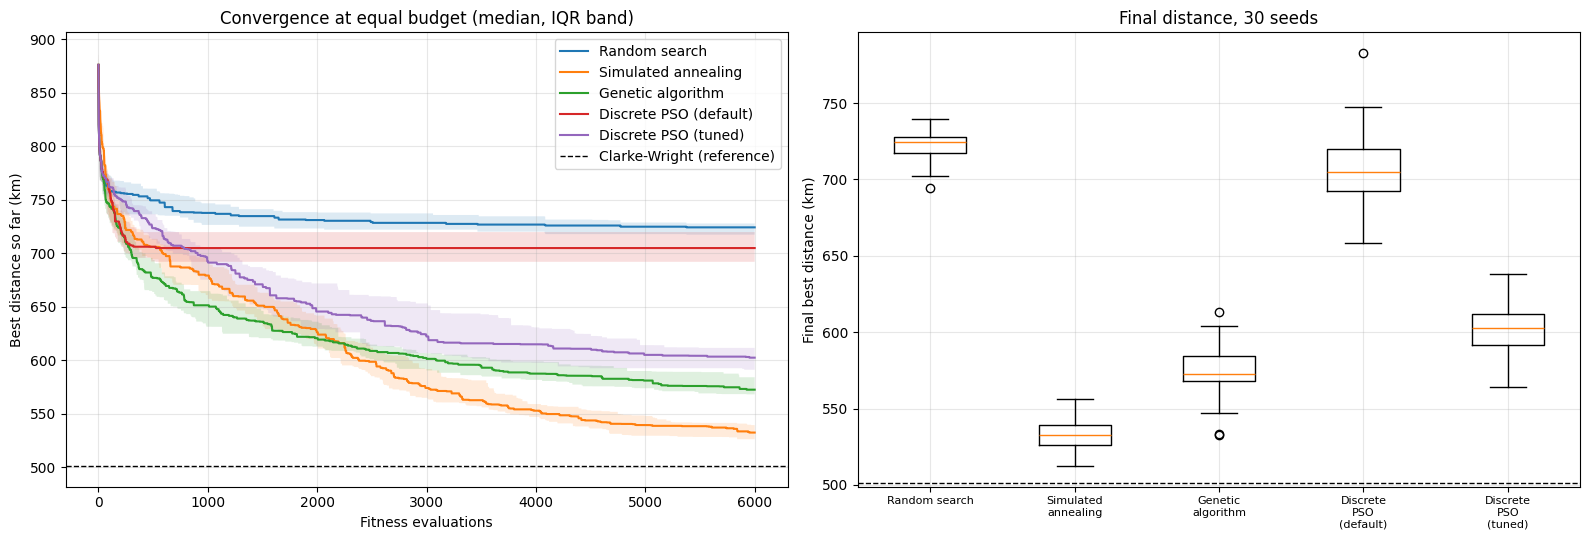

Best solution overall: Simulated annealing, 512.32 km
Best tuned-PSO solution: 564.20 km, 16 vehicles


In [22]:
rows = []
for name, runs in comparison.items():
    sc = np.array([r["best_score"] for r in runs]) / 1000
    rows.append({"algorithm": name, "mean_km": sc.mean(), "std_km": sc.std(ddof=1), "min_km": sc.min(),
                 "median_km": np.median(sc), "max_km": sc.max(),
                 "mean_vehicles": np.mean([r["vehicle_count"] for r in runs]), "runs": len(sc)})
summary = pd.DataFrame(rows).sort_values("mean_km").reset_index(drop=True)
best_known = summary["min_km"].min()
summary["gap_to_best_known_%"] = 100 * (summary["mean_km"] / best_known - 1)
rand_mean = summary.loc[summary.algorithm == "Random search", "mean_km"].iloc[0]
summary["improvement_vs_random_%"] = 100 * (1 - summary["mean_km"] / rand_mean)
print(f"Equal budget = {BUDGET} evaluations, {len(FINAL_SEEDS)} seeds per algorithm")
display(summary.round(3))
print(f"Clarke-Wright reference (no budget): {cw['total_distance'] / 1000:.3f} km, {cw['vehicle_count']} vehicles")
summary.to_csv(f"{OUT_DIR}/final_comparison_summary.csv", index=False)


def holm(pvals):
    order = np.argsort(pvals); m = len(pvals); adj = np.empty(m); running = 0.0
    for rank, idx in enumerate(order):
        running = max(running, (m - rank) * pvals[idx]); adj[idx] = min(1.0, running)
    return adj


from scipy.stats import mannwhitneyu
REF = "Discrete PSO (tuned)"
others = [n for n in comparison if n != REF]
ref_sc = np.array([r["best_score"] for r in comparison[REF]]) / 1000
pv = [mannwhitneyu(ref_sc, np.array([r["best_score"] for r in comparison[n]]) / 1000,
                   alternative="two-sided").pvalue for n in others]
stats_df = pd.DataFrame({
    "vs": others,
    "median_diff_km (PSO - other)": [np.median(ref_sc) - np.median([r["best_score"] for r in comparison[n]]) / 1000
                                     for n in others],
    "p_raw": pv, "p_holm": holm(np.array(pv))})
stats_df["significant@0.05"] = stats_df["p_holm"] < 0.05
print("Mann-Whitney U, tuned PSO vs each algorithm (negative diff = PSO shorter):")
display(stats_df.round(4))
stats_df.to_csv(f"{OUT_DIR}/final_comparison_stats.csv", index=False)

# convergence over evaluations (median + IQR)
fig, ax = plt.subplots(1, 2, figsize=(16, 5.5))
for name, runs in comparison.items():
    H = np.vstack([r["history"] for r in runs]) / 1000
    x = np.arange(1, H.shape[1] + 1)
    ax[0].plot(x, np.median(H, axis=0), label=name)
    ax[0].fill_between(x, np.percentile(H, 25, axis=0), np.percentile(H, 75, axis=0), alpha=0.15)
ax[0].axhline(cw["total_distance"] / 1000, color="k", ls="--", lw=1, label="Clarke-Wright (reference)")
ax[0].set_xlabel("Fitness evaluations"); ax[0].set_ylabel("Best distance so far (km)")
ax[0].set_title("Convergence at equal budget (median, IQR band)"); ax[0].grid(alpha=0.3); ax[0].legend()
ax[1].boxplot([[r["best_score"] / 1000 for r in comparison[n]] for n in comparison])
ax[1].set_xticks(range(1, len(comparison) + 1))
ax[1].set_xticklabels([n.replace(" (", "\n(").replace(" ", "\n", 1) if len(n) > 14 else n for n in comparison],
                      fontsize=8)
ax[1].axhline(cw["total_distance"] / 1000, color="k", ls="--", lw=1)
ax[1].set_ylabel("Final best distance (km)"); ax[1].set_title(f"Final distance, {len(FINAL_SEEDS)} seeds")
ax[1].grid(alpha=0.3)
fig.tight_layout(); fig.savefig(f"{OUT_DIR}/fig_final_comparison.png", dpi=150); plt.show()

# best solutions for the maps
all_runs = [(n, r) for n, rs in comparison.items() for r in rs]
GLOBAL_BEST_NAME, GLOBAL_BEST = min(all_runs, key=lambda t: t[1]["best_score"])
PSO_BEST = min(comparison[REF], key=lambda r: r["best_score"])
RAND_BEST = min(comparison["Random search"], key=lambda r: r["best_score"])
print(f"Best solution overall: {GLOBAL_BEST_NAME}, {GLOBAL_BEST['best_score'] / 1000:.2f} km")
print(f"Best tuned-PSO solution: {PSO_BEST['best_score'] / 1000:.2f} km, {PSO_BEST['vehicle_count']} vehicles")

# ORS + Folium route visualisation

In [28]:
import folium
from folium.features import DivIcon
import matplotlib.colors as mcolors

GEOM_CACHE_PATH = f"{OUT_DIR}/ors_route_geometries.json"
geom_cache = json.load(open(GEOM_CACHE_PATH)) if os.path.exists(GEOM_CACHE_PATH) else {}
PALETTE = [mcolors.to_hex(plt.get_cmap("tab20")(i)) for i in range(20)]
PALETTE = PALETTE[0::2] + PALETTE[1::2]


def route_geometry(route, use_ors=True):
    locs = [0] + [c + 1 for c in route] + [0]
    key = "-".join(map(str, locs))
    if key in geom_cache:
        return geom_cache[key]
    if use_ors:
        try:
            resp = client.directions(coordinates=[locations[i] for i in locs], profile="driving-car",
                                     format="geojson")
            feat = resp["features"][0]
            out = {"path": [[lat, lon] for lon, lat in feat["geometry"]["coordinates"]],
                   "ors_distance_m": feat["properties"]["summary"]["distance"], "source": "ORS directions"}
            geom_cache[key] = out
            json.dump(geom_cache, open(GEOM_CACHE_PATH, "w"))
            time.sleep(1.6)
            return out
        except Exception as e:
            print(f"  ORS directions failed for route {key[:40]}...: {str(e)[:120]} -> straight line")
    return {"path": [[locations[i][1], locations[i][0]] for i in locs],
            "ors_distance_m": None, "source": "straight line"}


def build_route_map(perm, title, filename, use_ors=True):
    routes = decode_solution(perm)
    depot_lat, depot_lon = df.iloc[0]["latitude"], df.iloc[0]["longitude"]
    m = folium.Map(location=[depot_lat, depot_lon], zoom_start=12,
                   tiles=CARTO_TILES, attr=CARTO_ATTR)
    table, legend_rows = [], []

    for k, route in enumerate(routes):
        color = PALETTE[k % len(PALETTE)]
        geo = route_geometry(route, use_ors)
        matrix_m = calculate_route_distance(route)
        load = int(sum(demands[c + 1] for c in route))
        label = f"Vehicle {k + 1}: {len(route)} stops, load {load}/{VEHICLE_CAPACITY}, {matrix_m / 1000:.1f} km"
        fg = folium.FeatureGroup(name=label, show=True)
        folium.PolyLine(geo["path"], color=color, weight=5, opacity=0.8,
                        tooltip=f"{label} [{geo['source']}]").add_to(fg)
        for stop, c in enumerate(route, start=1):
            row = df.iloc[c + 1]
            popup = (f"<b>{row['loc_name']}</b><br>ID {int(row['id'])}<br>Demand {int(row['demand'])}"
                     f"<br>Vehicle {k + 1}, stop {stop}")
            folium.CircleMarker([row["latitude"], row["longitude"]], radius=11, color=color, fill=True,
                                fill_color=color, fill_opacity=0.95, popup=folium.Popup(popup, max_width=260),
                                tooltip=f"V{k + 1}-{stop}: {row['loc_name']}").add_to(fg)
            folium.Marker([row["latitude"], row["longitude"]],
                          icon=DivIcon(icon_size=(22, 22), icon_anchor=(11, 11),
                                       html=f"<div style='font-size:10pt;color:white;text-align:center;"
                                            f"font-weight:bold;line-height:22px'>{stop}</div>")).add_to(fg)
        fg.add_to(m)
        legend_rows.append(f"<span style='color:{color}'>&#9632;</span> {label}")
        table.append({"vehicle": k + 1, "stops": len(route), "load": load,
                      "matrix_km": matrix_m / 1000,
                      "ors_directions_km": None if geo["ors_distance_m"] is None else geo["ors_distance_m"] / 1000,
                      "geometry": geo["source"],
                      "customer_ids": [int(df.iloc[c + 1]["id"]) for c in route]})

    folium.Marker([depot_lat, depot_lon], tooltip=f"Depot: {df.iloc[0]['loc_name']}",
                  icon=folium.Icon(color="black", icon="home")).add_to(m)
    total_km = sum(t["matrix_km"] for t in table)
    legend = (f"<div style='position:fixed;bottom:20px;left:20px;z-index:9999;background:white;padding:8px 12px;"
              f"border:1px solid #888;border-radius:6px;font-size:12px;max-height:45vh;overflow:auto'>"
              f"<b>{title}</b><br>Total {total_km:.1f} km, {len(routes)} vehicles<br>"
              + "<br>".join(legend_rows) + "</div>")
    m.get_root().html.add_child(folium.Element(legend))
    folium.LayerControl(collapsed=True).add_to(m)
    lats, lons = df["latitude"], df["longitude"]
    m.fit_bounds([[lats.min(), lons.min()], [lats.max(), lons.max()]])
    m.save(filename)
    tdf = pd.DataFrame(table)
    tdf["diff_%"] = 100 * (tdf["ors_directions_km"] / tdf["matrix_km"] - 1)
    return m, tdf

In [29]:
from google.colab import userdata

# CARTO basemaps now need an API key (appended as ?key=...). Falls back to plain OpenStreetMap if missing.
try:
    CARTO_KEY = userdata.get("carto_API_key")
except Exception:
    CARTO_KEY = None

if CARTO_KEY:
    CARTO_TILES = f"https://basemaps.cartocdn.com/rastertiles/light_all/{{z}}/{{x}}/{{y}}.png?key={CARTO_KEY}"
    CARTO_ATTR = "&copy; OpenStreetMap contributors, &copy; CARTO"
else:
    print("carto_API_key not found in Colab secrets -> using OpenStreetMap tiles.")
    CARTO_TILES = "OpenStreetMap"
    CARTO_ATTR = None

pso_map, pso_route_table = build_route_map(
    PSO_BEST["best_perm"], f"Tuned discrete PSO (best of {len(FINAL_SEEDS)})", f"{OUT_DIR}/map_pso_best.html")
display(pso_route_table.round(3))
pso_route_table.to_csv(f"{OUT_DIR}/pso_best_route_table.csv", index=False)
display(pso_map)

rand_map, rand_route_table = build_route_map(
    RAND_BEST["best_perm"], "Random search (best, same budget)", f"{OUT_DIR}/map_random_best.html")
display(rand_map)
print(f"PSO {pso_route_table.matrix_km.sum():.1f} km vs random search {rand_route_table.matrix_km.sum():.1f} km")

,vehicle,stops,load,matrix_km,ors_directions_km,geometry,customer_ids,diff_%
0,1,3,76,33.842,33.842,ORS directions,"[2088, 12677, 12728]",0.0
1,2,2,89,33.653,33.654,ORS directions,"[12726, 1974]",0.0
2,3,3,100,35.632,35.632,ORS directions,"[2032, 16119, 12694]",-0.0
3,4,4,98,41.930,41.930,ORS directions,"[12763, 226, 12746, 2024]",-0.0
4,5,3,100,31.368,31.368,ORS directions,"[2078, 12751, 12708]",-0.0
5,6,3,84,59.279,59.279,ORS directions,"[489, 2011, 3380]",0.0
6,7,3,95,25.909,25.909,ORS directions,"[12796, 2013, 2007]",0.0
7,8,4,94,57.059,57.059,ORS directions,"[12692, 2004, 1983, 2019]",-0.0
8,9,3,82,51.676,51.676,ORS directions,"[16163, 2009, 2167]",0.0
9,10,2,57,16.173,16.173,ORS directions,"[24, 12780]",0.0


PSO 564.2 km vs random search 694.3 km


# Final analysis and documentation

In [30]:
def md(dfx, digits=3):
    try:
        return dfx.round(digits).to_markdown(index=False)
    except Exception:
        return "```\n" + dfx.round(digits).to_string(index=False) + "\n```"


best_pso_ratio = PSO_BEST["best_score"] / 1000 / (cw["total_distance"] / 1000)
lines = [
    "# CVRP discrete PSO - results", "",
    "## Problem",
    f"- {N_CUSTOMERS} customers + 1 depot (`{df.iloc[0]['loc_name']}`), ORS `driving-car` road distances (asymmetric matrix)",
    f"- Synthetic demands U{{10..49}} (seed {RANDOM_SEED}), capacity {VEHICLE_CAPACITY}, total demand {int(demands.sum())}, "
    f"lower bound {int(np.ceil(demands.sum() / VEHICLE_CAPACITY))} vehicles",
    "- Objective: total travelled distance; encoding: customer permutation + greedy capacity split decoder", "",
    "## Experimental protocol",
    f"- Budget per run: **{BUDGET} fitness evaluations** for every metaheuristic",
    f"- Tuning seeds {TUNE_SEEDS[0]}..{TUNE_SEEDS[-1]}, confirmation seeds {CONFIRM_SEEDS[0]}..{CONFIRM_SEEDS[-1]}, "
    f"final comparison seeds {FINAL_SEEDS[0]}..{FINAL_SEEDS[-1]} ({len(FINAL_SEEDS)} runs/algorithm, disjoint from tuning)",
    f"- Default PSO: {DEFAULT_CFG}", f"- Tuned PSO: {TUNED_CFG}", "",
    "## Stage 3 baseline (100 random permutations)",
    f"- mean {baseline_df['total_distance'].mean() / 1000:.2f} km, best {baseline_df['total_distance'].min() / 1000:.2f} km, "
    f"mean vehicles {baseline_df['vehicle_count'].mean():.1f}", "",
    "## Stage 5 diagnostics (initial PSO runs)", md(diag_summary), "",
    "## Stage 6 tuning",
    "Top 10 grid configurations (km):", md(grid_summary.head(10)), "",
    "Top-3 confirmation (km):", md(confirm_summary), "",
    "Swarm size at fixed budget (km):", md(swarm_summary), "",
    "## Stage 7 equal-budget comparison (km)", md(summary), "",
    f"Clarke-Wright reference: {cw['total_distance'] / 1000:.3f} km, {cw['vehicle_count']} vehicles "
    f"(best tuned-PSO run is {100 * (best_pso_ratio - 1):+.1f}% vs CW).", "",
    "Mann-Whitney U, tuned PSO vs others (Holm-corrected):", md(stats_df, 4), "",
    "## Stage 8 best PSO solution", md(pso_route_table.drop(columns=["customer_ids"])), "",
    "Maps: `map_pso_best.html`, `map_random_best.html`.", "",
    "## Figures",
] + [f"- `{f}`" for f in sorted(os.listdir(OUT_DIR)) if f.endswith(".png")]
open(f"{OUT_DIR}/RESULTS.md", "w").write("\n".join(lines))
print("\n".join(lines[:40]), "\n...")

zip_path = f"{BASE_DIR}/cvrp_pso_results.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for fn in os.listdir(OUT_DIR):
        z.write(os.path.join(OUT_DIR, fn), fn)
print("Wrote", zip_path)
try:
    from google.colab import files
    files.download(zip_path)
except Exception:
    pass

# CVRP discrete PSO - results

## Problem
- 45 customers + 1 depot (`Indomarco`), ORS `driving-car` road distances (asymmetric matrix)
- Synthetic demands U{10..49} (seed 42), capacity 100, total demand 1364, lower bound 14 vehicles
- Objective: total travelled distance; encoding: customer permutation + greedy capacity split decoder

## Experimental protocol
- Budget per run: **6000 fitness evaluations** for every metaheuristic
- Tuning seeds 100..104, confirmation seeds 200..209, final comparison seeds 2000..2029 (30 runs/algorithm, disjoint from tuning)
- Default PSO: {'n_particles': 30, 'w': 0.7, 'c1': 1.5, 'c2': 1.5}
- Tuned PSO: {'n_particles': 50, 'w': 0.9, 'c1': 1.5, 'c2': 0.5}

## Stage 3 baseline (100 random permutations)
- mean 870.59 km, best 773.77 km, mean vehicles 16.8

## Stage 5 diagnostics (initial PSO runs)
|   run |   best_distance_km |   final_diversity |   first_iter_diversity<5% |   unique_positions_final |   last_gbest_improvement_iter |   stagnant_iters_% |   pa

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>